# Baseline Model: Logistic Regression on TF-IDF

This notebook builds and evaluates our baseline model, a Logistic Regression classifier trained on TF-IDF features extracted from article text. As an inherently interpretable model, it serves as both a performance reference point and a transparent benchmark for comparing against more complex models in later notebooks.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, recall_score
)

from preprocessing import (
    preprocess_text, get_tfidf_features,
    get_train_test_split, get_split_tfidf, RANDOM_STATE
)

import nltk
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

## 2. Load Cleaned Dataset

In [2]:
df = pd.read_csv("Dataset/fake_news_dataset_cleaned.csv")
df[["title", "text", "label", "label_encoded"]].head()

,title,text,label,label_encoded
0,Foreign Democrat final.,more tax development both store agreement lawy...,real,0
1,To offer down resource great point.,probably guess western behind likely next inve...,fake,1
2,Himself church myself carry.,them identify forward present success risk sev...,fake,1
3,You unit its should.,phone which item yard Republican safe where po...,fake,1
4,Billion believe employee summer how.,wonder myself fact difficult course forget exa...,fake,1


## 3. Text Preprocessing (NLP Pipeline)

Combine `title` + `text`, then apply: lowercasing → punctuation/special character removal → tokenization → stopword removal → lemmatization.

In [3]:
df["full_text"] = df["title"] + " " + df["text"]
df["processed_text"] = df["full_text"].apply(preprocess_text)
df[["full_text", "processed_text"]].head()

,full_text,processed_text
0,Foreign Democrat final. more tax development b...,foreign democrat final tax development store a...
1,To offer down resource great point. probably g...,offer resource great point probably guess west...
2,Himself church myself carry. them identify for...,church carry identify forward present success ...
3,You unit its should. phone which item yard Rep...,unit phone item yard republican safe police id...
4,Billion believe employee summer how. wonder my...,billion believe employee summer wonder fact di...


In [4]:
print("RAW:\n", df["full_text"].iloc[0][:300])
print("\nPROCESSED:\n", df["processed_text"].iloc[0][:300])

RAW:
 Foreign Democrat final. more tax development both store agreement lawyer hear outside continue reach difference yeah figure your power fear identify there protect security great national nothing fast story why late nearly bit cost tough since question to power almost future young conference behind a

PROCESSED:
 foreign democrat final tax development store agreement lawyer hear outside continue reach difference yeah figure power fear identify protect security great national nothing fast story late nearly bit cost tough since question power almost future young conference behind ahead building teach million b


## 4. TF-IDF Vectorization (Unigrams)

In [5]:
X, y, tfidf = get_tfidf_features(df)
print("TF-IDF matrix shape:", X.shape)

TF-IDF matrix shape: (20000, 867)


The final vocabulary has only 867 terms. Because the text is made of loosely random word sequences, almost no word pair repeats often enough to pass the frequency filter, so in practice the model runs on unigrams.

## 5. Train/Test Split

Fixed `random_state` and `stratify=y` ensure this exact split is reused identically across every model in this project.

In [6]:
X_train, X_test, y_train, y_test, tfidf = get_split_tfidf(df)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTrain class balance:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest class balance:\n", y_test.value_counts(normalize=True).round(3))

Train shape: (16000, 867)
Test shape: (4000, 867)

Train class balance:
 label_encoded
1    0.503
0    0.497
Name: proportion, dtype: float64

Test class balance:
 label_encoded
1    0.503
0    0.497
Name: proportion, dtype: float64


## 6. Train Baseline Model: Logistic Regression

In [7]:
log_reg = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)
log_reg.fit(X_train, y_train)

y_pred = log_reg.predict(X_test)

## 7. Evaluation

Recall on the **Fake** class (`label_encoded = 1`) is the primary metric, per the project's trust-and-safety framing.

In [8]:
print(classification_report(y_test, y_pred, target_names=["real", "fake"]))

recall_fake = recall_score(y_test, y_pred, pos_label=1)
print(f"Recall on Fake class (primary metric): {recall_fake:.4f}")

              precision    recall  f1-score   support

        real       0.50      0.48      0.49      1989
        fake       0.50      0.52      0.51      2011

    accuracy                           0.50      4000
   macro avg       0.50      0.50      0.50      4000
weighted avg       0.50      0.50      0.50      4000

Recall on Fake class (primary metric): 0.5162


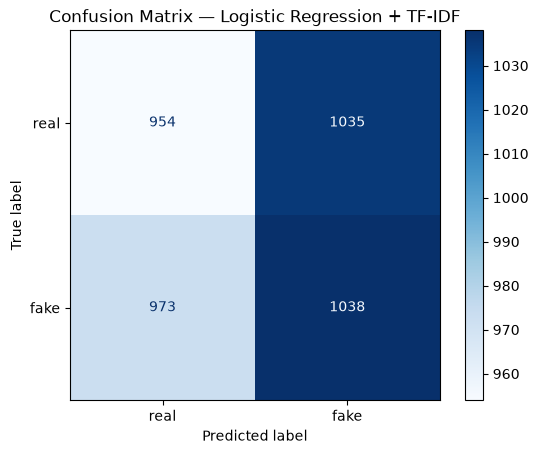

In [9]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["real", "fake"])
disp.plot(cmap="Blues")
plt.title("Confusion Matrix — Logistic Regression + TF-IDF")
plt.show()

- True Positive, correctly caught fake news article: 1,038
- False Negative, fake news article predicted as real: 973
- False Positive, real article predicted as fake: 1,035
- True Negative, correctly identified real article: 954

The model catches 51.6% of fake articles (recall = 0.5162), and only about half of its “fake” flags are actually fake (precision ≈ 0.50). Overall accuracy is 49.8%.

For context, the test set is 50.3% fake. A model that simply labels everything as fake would get 50.3% accuracy and 100% fake recall. Our baseline does slightly worse than that trivial rule on accuracy. This is also why recall should never be reported alone: it is easy to max out by flagging everything.

The errors are split almost evenly across all four cells, which is what random guessing looks like in a confusion matrix. For a trust-and-safety reviewer, this means roughly every other fake article slips through and every other flag is a false alarm. The model is not usable as it stands.

### 7.1 Sanity Check: Is There Any Signal?

Before reading anything into the coefficients, we check whether the model learned anything at all. We compare it against (1) a dummy model that always predicts "fake," and (2) the same logistic regression trained on **shuffled labels**, where any real link between text and label is destroyed on purpose.

In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import permutation_test_score, StratifiedKFold

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"Dummy (always 'fake') accuracy: {dummy.score(X_test, y_test):.4f}")

score, perm_scores, p_value = permutation_test_score(
    LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
    X_train, y_train, scoring="accuracy",
    cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
    n_permutations=100, random_state=RANDOM_STATE, n_jobs=-1
)
print(f"CV accuracy (real labels):     {score:.4f}")
print(f"CV accuracy (shuffled labels): {perm_scores.mean():.4f}")
print(f"p-value: {p_value:.3f}")

Dummy (always 'fake') accuracy: 0.5028
CV accuracy (real labels):     0.5046
CV accuracy (shuffled labels): 0.4991
p-value: 0.158


The model's cross-validated accuracy on the real labels (0.5046) is about the same as on shuffled labels (0.4991) and barely above the always-predict-"fake" dummy (0.5028), with p = 0.158. In other words, the model does no better than chance. The text carries no learnable fake/real signal, so the ~50% result reflects the data, not a weak model. The coefficients in Section 8 should be read with this in mind.

## 8. Interpretability: Coefficients → Odds Ratios

Since logistic regression is inherently interpretable, no post-hoc explanation method is needed. Coefficients map directly to specific words/n-grams.

In [11]:
feature_names = tfidf.get_feature_names_out()
coefficients = log_reg.coef_[0]

coef_df = pd.DataFrame({
    "term": feature_names,
    "coefficient": coefficients,
    "odds_ratio": np.exp(coefficients)
})

print("Top 15 terms pushing toward FAKE (label_encoded=1):")
display(coef_df.sort_values("coefficient", ascending=False).head(15))

print("\nTop 15 terms pushing toward REAL (label_encoded=0):")
display(coef_df.sort_values("coefficient", ascending=True).head(15))

Top 15 terms pushing toward FAKE (label_encoded=1):


,term,coefficient,odds_ratio
528,particular,1.378175,3.967654
683,significant,1.323998,3.758418
464,model,1.249214,3.487601
736,stop,1.202394,3.328075
860,wrong,1.089866,2.973875
281,fire,1.067196,2.907215
263,far,1.062544,2.893723
36,animal,1.054010,2.869133
638,rich,1.036525,2.819401
17,agency,1.011494,2.749705



Top 15 terms pushing toward REAL (label_encoded=0):


,term,coefficient,odds_ratio
220,economy,-1.327948,0.265020
83,big,-1.291802,0.274775
77,behind,-1.154067,0.315352
523,painting,-1.105803,0.330945
618,reflect,-1.072386,0.342191
311,girl,-1.054595,0.348334
97,bring,-1.025730,0.358534
156,congress,-0.999243,0.368158
250,example,-0.995618,0.369495
707,son,-0.972673,0.378071


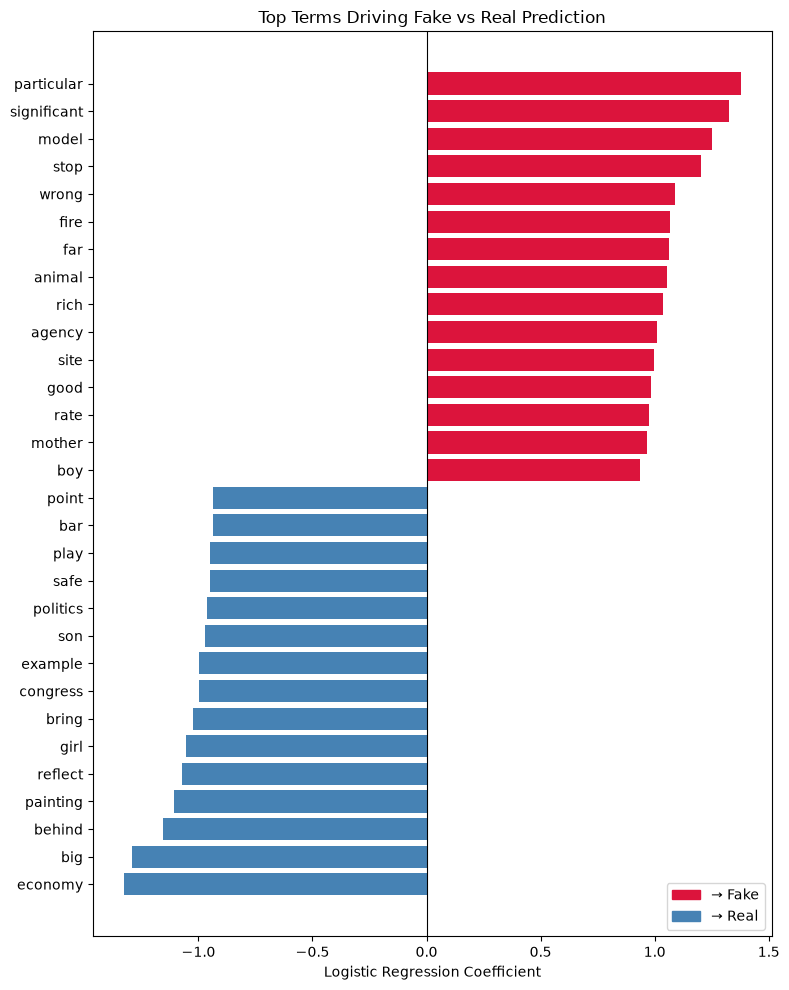

In [12]:
top_n = 15
top_fake = coef_df.nlargest(top_n, "coefficient")   # positive → pushes toward FAKE (1)
top_real = coef_df.nsmallest(top_n, "coefficient")  # negative → pushes toward REAL (0)
plot_df = pd.concat([top_real, top_fake]).sort_values("coefficient")

plt.figure(figsize=(8, 10))
colors = ["crimson" if c > 0 else "steelblue" for c in plot_df["coefficient"]]
plt.barh(plot_df["term"], plot_df["coefficient"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)

from matplotlib.patches import Patch
plt.legend(handles=[Patch(color="crimson", label="→ Fake"),
                    Patch(color="steelblue", label="→ Real")], loc="lower right")
plt.title("Top Terms Driving Fake vs Real Prediction")
plt.xlabel("Logistic Regression Coefficient")
plt.tight_layout()
plt.show()

The top coefficients show no meaningful linguistic pattern. Words pushing toward “fake” (particular, significant, model, stop, wrong) and toward “real” (economy, big, behind, painting, girl) are ordinary everyday words. None of them are the signals we would expect from fabricated news, such as sensational language, urgency cues, or emotional phrasing. Pairs like boy → fake and girl/son → real are a good sign that we are looking at noise rather than real patterns.

Note on odds ratios: an odds ratio is the change in odds for a 1.0 increase in that word’s TF-IDF weight. Real TF-IDF weights for a single word are usually far below 1, so an odds ratio of ~4 for “particular” overstates its practical effect. These values are best read as a ranking of which words the model leans on, not as “this word makes an article X times more likely to be fake.”

This fits the model’s coin-flip performance (fake recall ≈ 52%, accuracy ≈ 50%). With 16,000 training articles and 867 features, a logistic regression will always find some words with non-zero weights even when the labels are random. The text itself also looks auto-generated: both titles and bodies read as random sequences of common English words rather than real sentences. The most likely explanation is that the dataset is synthetic and the labels were assigned independently of the text. If so, no model, however complex, will beat ~50%, and the later notebooks should be read with that in mind.

This can be checked directly (see the sanity-check cell below) before more complex models are trained.

The top 15 terms in each direction are ordinary words, with no outlet names, bylines, URLs, or other identifiers, so there is no sign of a shortcut (data leakage) in the highest-weighted features. This only covers the top of the list. Because overall performance is near chance, though, a strong hidden shortcut is unlikely: if one existed, the model would be exploiting it and scoring much higher.

### Why No LIME/SHAP/PDP/ICE for Logistic Regression

Logistic regression is interpretable by design: each coefficient tells us exactly how a word shifts the log-odds of “fake,” with no approximation. This gives us the global explanation directly. For a single article, the explanation is just as direct: multiply each word’s coefficient by its TF-IDF weight in that article and add them up. That is exactly the model’s score.

Post-hoc tools like LIME, PDP, and ICE exist to probe black-box models from the outside, so they add little here. (SHAP on a linear model reduces to essentially the coefficient × feature calculation above.) These tools become necessary from the next tier onward (Random Forest, XGBoost, LightGBM, non-linear SVM), where the model’s internals no longer explain its predictions directly. A single shallow Decision Tree is the exception, since it can be read directly as well.

## Summary

This notebook set our baseline: a Logistic Regression on TF-IDF features. It reached a Fake-class recall of 0.516 and an accuracy of 0.498, no better than always predicting "fake" (0.503). The permutation test (p = 0.158) confirms the model learned no real signal from the text, so the ~50% score reflects the data, not the model. Every later model will be compared against this baseline, and any result well above 50% should be checked for data leakage before it's trusted.